# Compression analysis: is it the handwriting evidence or just less merging?

**Compression** = characters ÷ tokens, i.e. how many characters one token covers on average. Plain characters give **1.00**; the more a tokenizer merges, the higher the number.

On ED the character baseline has the lowest error. If tokenization itself hurts on ED, the tokenizer that merges *least* will look best, whatever evidence chose its tokens. Handwriting-aware tokenizers merge less than their text-only partners, so their advantage could come from compression alone.

| Section | Question |
| --- | --- |
| 1 | How much does each tokenizer compress IAM text and ED labels? |
| 2 | Does recognition error simply follow compression? Do handwriting tokenizers do better than their compression predicts? |
| 3 | How large must a text-only tokenizer be to compress exactly like its handwriting partner? (the fair control to train next) |
| 4 | Summary in words |

Nothing is trained. Section 1 needs only the bundled tokenizer files (ED columns need the extracted ED data). Section 2 reads the CER/WER saved during training under `results/thesis/ed/`; no model is run.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from loguru import logger

from tva.ed_analysis import (TOKENIZERS, bigram_compression_curve, bpe_compression_curve, characters_per_token,
                             iam_training_texts, load_records, load_tokenizer, saved_scores, show_table)

logger.disable('tva')  # hide routine 'tokenizer loaded' messages

# ---- Settings: change these, then run all cells ----
SPLITS = ['wd', 'wi']
FOLDS = [0, 1, 2, 3, 4]   # only folds completed by every plotted tokenizer are used
METRIC = 'cer'            # 'cer' or 'wer' for section 2

NAMES = {
    'character': 'Character',
    'handwriting_bigram': 'HW bigram', 'handwriting_bpe': 'HW BPE', 'handwriting_unigram': 'HW Unigram',
    'linguistic_bigram_tva': 'Text bigram (original TVA)',
    'linguistic_bigram_iam_frequency': 'Text bigram (IAM count)',
    'linguistic_bpe': 'Text BPE', 'linguistic_unigram': 'Text Unigram',
}
EVIDENCE = {c: 'character' if c == 'character' else c.split('_')[0] for c in NAMES}
COLOURS = {'character': 'grey', 'handwriting': 'tab:orange', 'linguistic': 'tab:blue'}

tokenizers = {c: load_tokenizer(c) for c in TOKENIZERS}
iam_texts = iam_training_texts()
try:
    # WD and WI contain the same 2,550 recordings; fold 0 train + val covers all of them.
    ed_texts = [r['label'] for part in ('train', 'val') for r in load_records('wd', 0, part)]
except FileNotFoundError:
    ed_texts = []
    print('Extracted ED data not found: ED columns are skipped, IAM compression is used instead.')
print(f'{len(iam_texts)} IAM training lines, {len(ed_texts)} ED recordings')

5612 IAM training lines, 2550 ED recordings


## 1. Compression of every tokenizer

- **IAM** — the training text every tokenizer learned from (lines with IAM-only symbols `#`, `&`, `*` are left out).
- **ED** — all 2,550 ED recordings, i.e. the actual recognition targets.

Higher = more merging = shorter label sequences. All learned tokenizers have the same 145-piece budget, so differences come from *which* pieces were chosen.

| Tokenizer | Evidence | Characters per token, IAM | Characters per token, ED | Tokens per ED sentence |
| --- | --- | --- | --- | --- |
| Character | character | 1.000 | 1.000 | 41.6 |
| HW bigram | handwriting | 1.335 | 1.246 | 33.4 |
| HW BPE | handwriting | 1.378 | 1.263 | 32.9 |
| HW Unigram | handwriting | 1.365 | 1.251 | 33.3 |
| Text bigram (original TVA) | linguistic | 1.713 | 1.499 | 27.8 |
| Text bigram (IAM count) | linguistic | 1.472 | 1.342 | 31.0 |
| Text BPE | linguistic | 1.553 | 1.372 | 30.3 |
| Text Unigram | linguistic | 1.554 | 1.372 | 30.3 |

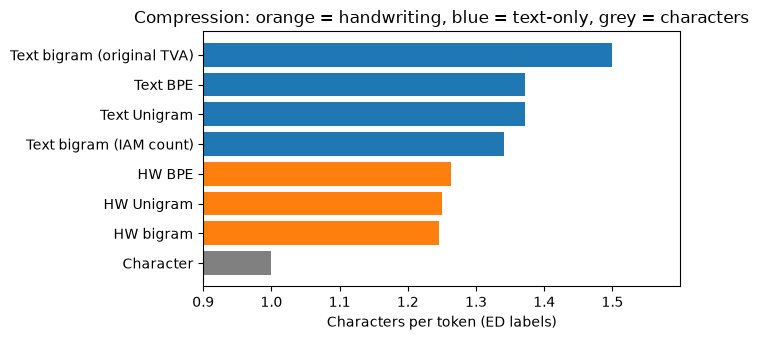

In [2]:
compression = {}
rows = []
for c, t in tokenizers.items():
    iam = characters_per_token(t, iam_texts)
    ed = characters_per_token(t, ed_texts) if ed_texts else None
    compression[c] = ed or iam
    rows.append({'Tokenizer': NAMES[c], 'Evidence': EVIDENCE[c],
                 'Characters per token, IAM': f'{iam:.3f}',
                 'Characters per token, ED': f'{ed:.3f}' if ed else '-',
                 'Tokens per ED sentence': f'{sum(len(t.encode(x)) for x in ed_texts) / len(ed_texts):.1f}' if ed_texts else '-'})
show_table(rows)
basis = 'ED labels' if ed_texts else 'IAM text'

order = sorted(compression, key=compression.get)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.barh([NAMES[c] for c in order], [compression[c] for c in order],
        color=[COLOURS[EVIDENCE[c]] for c in order])
ax.set_xlim(0.9, max(compression.values()) + 0.1)
ax.set_xlabel(f'Characters per token ({basis})')
ax.set_title('Compression: orange = handwriting, blue = text-only, grey = characters')
plt.tight_layout()
plt.show()

## 2. Does recognition error simply follow compression?

Each point is one tokenizer: **x = compression**, **y = validation error**, averaged over the folds that *every* plotted tokenizer has completed (listed above the plot). Scores are taken at each run's lowest-CER epoch, with WER from that same epoch.

The grey line is a straight-line fit through the **character and text-only** tokenizers only — the tokenizers that use no handwriting evidence. It shows what error to *expect* from compression alone.

- A handwriting point **below** the line: lower error than its compression predicts → the handwriting evidence adds something.
- A handwriting point **on** the line: its advantage is explained by compression.
- **Above** the line: worse than compression predicts.

With only about five reference points, the line is a rough guide, not a statistical model.

In [3]:
key = {'cer': 'cer', 'wer': 'wer'}[METRIC]
results = {}
for split in SPLITS:
    scores = {c: {f: s for f in FOLDS if (s := saved_scores(c, split, f))} for c in NAMES}
    present = [c for c in NAMES if scores[c]]
    folds = sorted(set(FOLDS).intersection(*(scores[c] for c in present))) if present else []
    results[split] = {
        'folds': folds,
        'mean': {c: 100 * np.mean([scores[c][f][key] for f in folds]) for c in present} if folds else {},
    }

rows = []
for c in NAMES:
    row = {'Tokenizer': NAMES[c], 'Characters per token': f'{compression[c]:.3f}'}
    for split in SPLITS:
        value = results[split]['mean'].get(c)
        row[f'{split.upper()} {METRIC.upper()} (%)'] = f'{value:.2f}' if value is not None else '-'
    rows.append(row)
for split in SPLITS:
    print(f"{split.upper()}: folds used {results[split]['folds'] or 'none (no common completed folds)'}")
show_table(rows)

WD: folds used [0]
WI: folds used [0]


| Tokenizer | Characters per token | WD CER (%) | WI CER (%) |
| --- | --- | --- | --- |
| Character | 1.000 | 15.85 | 13.71 |
| HW bigram | 1.246 | 24.27 | 16.42 |
| HW BPE | 1.263 | 24.45 | 17.18 |
| HW Unigram | 1.251 | 24.07 | 16.84 |
| Text bigram (original TVA) | 1.499 | 35.96 | 20.93 |
| Text bigram (IAM count) | 1.342 | 32.20 | 18.60 |
| Text BPE | 1.372 | 28.97 | 18.01 |
| Text Unigram | 1.372 | 30.12 | 18.71 |

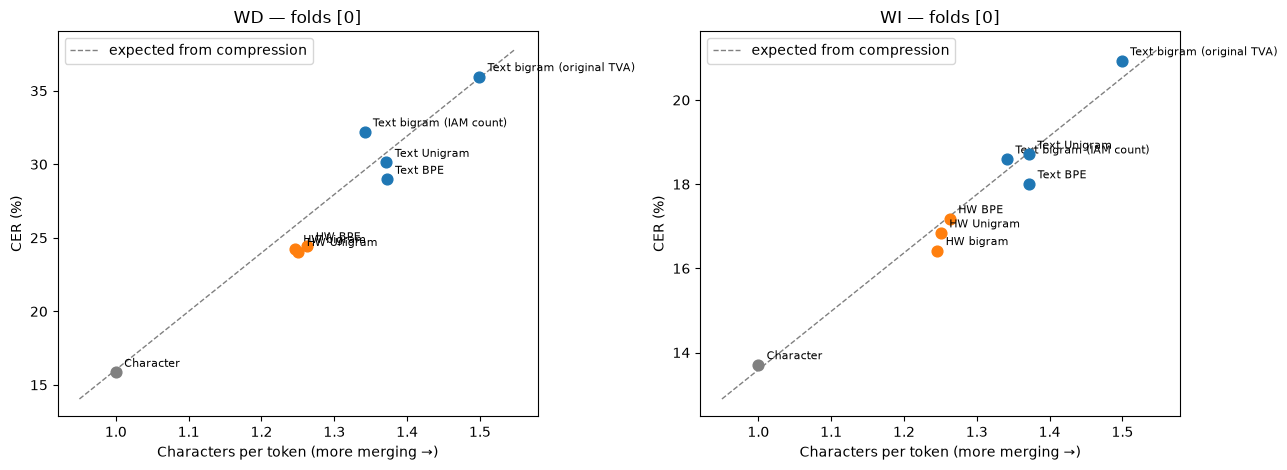

| Split | Handwriting tokenizer | Actual CER (%) | Expected from compression (%) | Difference (pp) | Reading |
| --- | --- | --- | --- | --- | --- |
| WD | HW bigram | 24.27 | 25.80 | -1.53 | better than compression predicts |
| WD | HW BPE | 24.45 | 26.48 | -2.03 | better than compression predicts |
| WD | HW Unigram | 24.07 | 25.99 | -1.93 | better than compression predicts |
| WI | HW bigram | 16.42 | 17.00 | -0.58 | better than compression predicts |
| WI | HW BPE | 17.18 | 17.24 | -0.07 | better than compression predicts |
| WI | HW Unigram | 16.84 | 17.07 | -0.23 | better than compression predicts |

In [4]:
fig, axes = plt.subplots(1, len(SPLITS), figsize=(6.5 * len(SPLITS), 4.8), squeeze=False)
residuals = []
for ax, split in zip(axes[0], SPLITS):
    mean = results[split]['mean']
    reference = [c for c in mean if EVIDENCE[c] != 'handwriting']
    for c, value in mean.items():
        ax.scatter(compression[c], value, s=60, color=COLOURS[EVIDENCE[c]], zorder=3)
        ax.annotate(NAMES[c], (compression[c], value), textcoords='offset points', xytext=(6, 4), fontsize=8)
    if len(reference) >= 2:
        slope, intercept = np.polyfit([compression[c] for c in reference], [mean[c] for c in reference], 1)
        xs = np.linspace(0.95, max(compression.values()) + 0.05, 50)
        ax.plot(xs, slope * xs + intercept, color='grey', lw=1, ls='--', label='expected from compression')
        for c in mean:
            if EVIDENCE[c] == 'handwriting':
                expected = slope * compression[c] + intercept
                residuals.append({'split': split, 'condition': c, 'actual': mean[c],
                                  'expected': expected, 'difference': mean[c] - expected})
        ax.legend(loc='upper left')
    ax.set_xlabel('Characters per token (more merging →)')
    ax.set_ylabel(f'{METRIC.upper()} (%)')
    ax.set_title(f"{split.upper()} — folds {results[split]['folds']}")
plt.tight_layout()
plt.show()

show_table([{'Split': r['split'].upper(), 'Handwriting tokenizer': NAMES[r['condition']],
             f'Actual {METRIC.upper()} (%)': f"{r['actual']:.2f}",
             'Expected from compression (%)': f"{r['expected']:.2f}",
             'Difference (pp)': f"{r['difference']:+.2f}",
             'Reading': 'better than compression predicts' if r['difference'] < 0 else 'explained by compression or worse'}
            for r in residuals])

## 3. Compression-matched text-only controls

The fair way to remove the compression effect is to compare each handwriting tokenizer with a text-only tokenizer that **compresses the same amount**. Two text-only tokenizers can be shrunk exactly, without retraining:

- **Text bigram (IAM count)** keeps its top *k* bigrams by IAM count — the same as selecting *k* instead of 145 bigrams.
- **Text BPE** keeps its first *k* merges — BPE learns merges one at a time, so this equals training with a budget of *k*.

Text Unigram cannot be shrunk this way; it would need retraining with a smaller budget.

The size *k* is chosen on **IAM text only**, so no ED label influences it. ED compression is shown for information.

| Family | Handwriting, IAM | Text-only (145 pieces), IAM | Matched text-only size k | Matched, IAM | Matched, ED | Handwriting, ED |
| --- | --- | --- | --- | --- | --- | --- |
| Bigram | 1.335 | 1.472 | 62 | 1.335 | 1.244 | 1.246 |
| BPE | 1.378 | 1.553 | 59 | 1.379 | 1.257 | 1.263 |

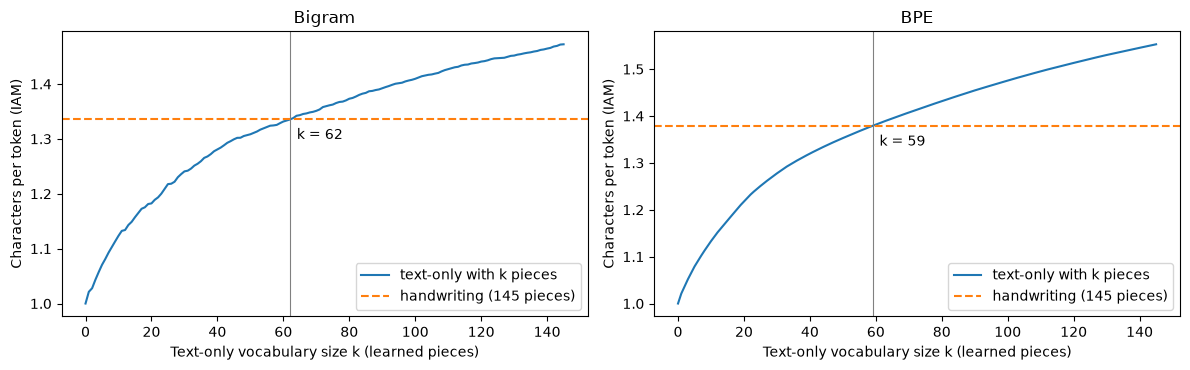

In [5]:
bigram_model = tokenizers['linguistic_bigram_iam_frequency'].model
ranked_bigrams = [row['token'] for row in sorted(bigram_model['vocabulary'], key=lambda r: r['rank'])]
text_merges = tokenizers['linguistic_bpe'].source_model['merges']

# family: (handwriting tokenizer, IAM compression for k = 0..145, ED compression at size k)
controls = {
    'Bigram': ('handwriting_bigram', bigram_compression_curve(iam_texts, ranked_bigrams),
               lambda k: bigram_compression_curve(ed_texts, ranked_bigrams[:k])[-1]),
    'BPE': ('handwriting_bpe', bpe_compression_curve(iam_texts, text_merges),
            lambda k: bpe_compression_curve(ed_texts, text_merges[:k])[-1]),
}
rows, curves = [], {}
for family, (hw, curve, ed_at) in controls.items():
    target = characters_per_token(tokenizers[hw], iam_texts)
    best = min(range(len(curve)), key=lambda k: (abs(curve[k] - target), k))
    curves[family] = (curve, target, best)
    rows.append({'Family': family,
                 'Handwriting, IAM': f'{target:.3f}',
                 'Text-only (145 pieces), IAM': f'{curve[-1]:.3f}',
                 'Matched text-only size k': best,
                 'Matched, IAM': f'{curve[best]:.3f}',
                 'Matched, ED': f'{ed_at(best):.3f}' if ed_texts else '-',
                 'Handwriting, ED': f'{characters_per_token(tokenizers[hw], ed_texts):.3f}' if ed_texts else '-'})
show_table(rows)

fig, axes = plt.subplots(1, len(curves), figsize=(6 * len(curves), 3.8), squeeze=False)
for ax, (family, (curve, target, best)) in zip(axes[0], curves.items()):
    ax.plot(range(len(curve)), curve, color=COLOURS['linguistic'], label='text-only with k pieces')
    ax.axhline(target, color=COLOURS['handwriting'], ls='--', label='handwriting (145 pieces)')
    ax.axvline(best, color='grey', lw=0.8)
    ax.annotate(f'k = {best}', (best, target), textcoords='offset points', xytext=(5, -14))
    ax.set_xlabel('Text-only vocabulary size k (learned pieces)')
    ax.set_ylabel('Characters per token (IAM)')
    ax.set_title(family)
    ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

## 4. Summary in words

In [6]:
hw = [c for c in NAMES if EVIDENCE[c] == 'handwriting']
text = [c for c in NAMES if EVIDENCE[c] == 'linguistic']
lines = [
    f'- Handwriting tokenizers cover **{min(compression[c] for c in hw):.2f}–{max(compression[c] for c in hw):.2f}** '
    f'characters per token on {basis}; text-only tokenizers cover **{min(compression[c] for c in text):.2f}–'
    f'{max(compression[c] for c in text):.2f}**. Handwriting tokenizers therefore merge '
    f'{"less" if max(compression[c] for c in hw) < min(compression[c] for c in text) else "about as much"}.',
]
for split in SPLITS:
    mean = results[split]['mean']
    if len(mean) >= 3:
        r = np.corrcoef([compression[c] for c in mean], list(mean.values()))[0, 1]
        lines.append(f'- {split.upper()} (folds {results[split]["folds"]}): the correlation between compression and '
                     f'{METRIC.upper()} across {len(mean)} tokenizers is **{r:+.2f}**: a '
                     f'{"weak" if abs(r) < 0.3 else "moderate" if abs(r) < 0.7 else "strong"} tendency for '
                     f'{"more merging to go with higher error" if r > 0 else "more merging to go with lower error"}.')
for r in residuals:
    lines.append(f"- {r['split'].upper()}, {NAMES[r['condition']]}: {abs(r['difference']):.2f} pp "
                 f"{'below' if r['difference'] < 0 else 'above'} the compression line "
                 f"({'better than compression alone predicts' if r['difference'] < 0 else 'no advantage beyond compression'}).")
for family, (curve, target, best) in curves.items():
    lines.append(f'- A text-only {family} with **{best}** pieces compresses IAM text like the handwriting {family} '
                 f'({curve[best]:.3f} vs {target:.3f}). Training recognizers with it is the compression-matched test.')
lines.append('- These are fold-level descriptions, not statistical tests; use all five folds before drawing conclusions.')
display(Markdown('\n'.join(lines)))

- Handwriting tokenizers cover **1.25–1.26** characters per token on ED labels; text-only tokenizers cover **1.34–1.50**. Handwriting tokenizers therefore merge less.
- WD (folds [0]): the correlation between compression and CER across 8 tokenizers is **+0.97**: a strong tendency for more merging to go with higher error.
- WI (folds [0]): the correlation between compression and CER across 8 tokenizers is **+0.98**: a strong tendency for more merging to go with higher error.
- WD, HW bigram: 1.53 pp below the compression line (better than compression alone predicts).
- WD, HW BPE: 2.03 pp below the compression line (better than compression alone predicts).
- WD, HW Unigram: 1.93 pp below the compression line (better than compression alone predicts).
- WI, HW bigram: 0.58 pp below the compression line (better than compression alone predicts).
- WI, HW BPE: 0.07 pp below the compression line (better than compression alone predicts).
- WI, HW Unigram: 0.23 pp below the compression line (better than compression alone predicts).
- A text-only Bigram with **62** pieces compresses IAM text like the handwriting Bigram (1.335 vs 1.335). Training recognizers with it is the compression-matched test.
- A text-only BPE with **59** pieces compresses IAM text like the handwriting BPE (1.379 vs 1.378). Training recognizers with it is the compression-matched test.
- These are fold-level descriptions, not statistical tests; use all five folds before drawing conclusions.